# 🎨 06 — Model 3: K-Means Style Clustering
### Scouti Kora — AI Football Scouting System

**What this model does:**
Groups players by **playing style** within each position — not by quality.
Two players can both score 70/100 talent but play completely differently.
This model finds those natural style groups automatically.

**Design decisions:**
- Run K-Means **separately per position** — a Forward cluster has no meaning next to a GK cluster
- Use **multi-hot positions** — MF,FW player appears in BOTH Forward AND Midfielder clustering
- Use **only per-90 stats** for clustering (same philosophy as KNN — style not volume)
- Find optimal K using **Elbow Method + Silhouette Score** per position
- **Name each cluster** based on the centroid stats profile
- Use **PCA 2D** to visualize clusters

**Expected clusters:**
```
Forwards:    Pure Poacher | Complete Forward | Wide Forward | Target Man
Midfielders: Deep Playmaker | Box-to-Box | Creative #10 | Pressing Machine
Defenders:   Ball-Playing CB | Aggressive Stopper | Attacking FB
Goalkeepers: Shot-stopper | Sweeper Keeper
```

---
**Input:** `data/processed/master_scouting_dataset.csv`  
**Output:** `data/processed/style_clusters.csv` + `data/processed/cluster_models.pkl`

## 📦 0 — Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pickle
import warnings
import json
from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)

ROOT      = Path('..').resolve()
PROCESSED = ROOT / 'data' / 'processed'
REPORTS   = ROOT / 'reports'

COLORS = ['#7F77DD','#1D9E75','#D85A30','#378ADD','#BA7517','#D4537E',
           '#9B59B6','#1ABC9C','#E67E22','#2ECC71']
plt.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':'white',
    'axes.grid':True,'grid.alpha':0.3,
    'axes.spines.top':False,'axes.spines.right':False,
})
print('✅ Ready')

✅ Ready


## 📂 1 — Load Master Dataset

In [2]:
df = pd.read_csv(PROCESSED / 'master_scouting_dataset.csv', low_memory=False)
print(f'Master dataset: {len(df):,} rows × {len(df.columns)} cols')
print(f'Unique players: {df["Player"].nunique():,}')

# Load talent scores to enrich cluster output
talent_path = PROCESSED / 'talent_scores.csv'
if talent_path.exists():
    talent_df = pd.read_csv(talent_path)
    print(f'Talent scores:  {len(talent_df):,} players')
else:
    talent_df = pd.DataFrame()
    print('⚠️  talent_scores.csv not found — run notebook 05 first')

# Latest season per player (same as NB04)
SEASON_ORDER = {
    '2020-2021':1,'2021-2022':2,'2022-2023':3,'2023-2024':4,'2024-2025':5
}
df['season_rank'] = df['season'].map(SEASON_ORDER).fillna(0)
player_latest = (
    df.sort_values('season_rank', ascending=False)
    .drop_duplicates('Player', keep='first')
    .reset_index(drop=True)
)
print(f'Unique players (latest season): {len(player_latest):,}')

Master dataset: 11,888 rows × 69 cols
Unique players: 4,817
Talent scores:  4,677 players
Unique players (latest season): 4,817


## 🎯 2 — Clustering Feature Set
**Rule:** Per-90 stats only — captures style, not volume.
Different feature subsets per position — GK needs different features than FW.

In [3]:
# ── Position-specific feature sets ──────────────────────
# Each position group uses features most relevant to THAT position's playing style

CLUSTER_FEATURES = {
    'Forward': [
        'goals_p90',          # pure scorer vs distributor
        'assists_p90',        # creative vs selfish
        'shots_p90',          # volume shooter vs efficient finisher
        'shot_accuracy_pct',  # precision
        'conversion_rate',    # clinical vs wasteful
        'g_a_p90',            # total contribution
        'tackles_won_p90',    # pressing forward vs passive
        'yellow_p90',         # aggressive vs composed
        'availability_pct',   # reliable vs injury-prone
    ],
    'Midfielder': [
        'goals_p90',          # goal-threat vs pure passer
        'assists_p90',        # creative vs defensive
        'g_a_p90',            # attacking contribution
        'shots_p90',          # box-to-box vs deep-lying
        'tackles_won_p90',    # defensive midfielder vs #10
        'interceptions_p90',  # reading game vs ball-playing
        'def_actions_p90',    # total defensive work rate
        'yellow_p90',         # aggressive vs composed
        'availability_pct',
    ],
    'Defender': [
        'goals_p90',          # attacking CB vs stay-back CB
        'assists_p90',        # overlapping FB vs conservative
        'tackles_won_p90',    # aggressive vs positional
        'interceptions_p90',  # ball-hawk vs line-holder
        'def_actions_p90',    # total defensive work
        'yellow_p90',         # aggressive vs disciplined
        'availability_pct',
        'shot_accuracy_pct',  # ball-playing vs clearance CB
    ],
    'Goalkeeper': [
        'availability_pct',   # reliable vs rotated
        'goals_p90',          # shots conceded proxy (inverted signal)
        'yellow_p90',         # aggressive vs calm
        'def_actions_p90',    # sweeper keeper vs stay-on-line
    ],
}

# Multi-hot position columns → used to assign each player to their position group(s)
POS_COL_MAP = {
    'Forward':    'pos_FW',
    'Midfielder': 'pos_MF',
    'Defender':   'pos_DF',
    'Goalkeeper': 'pos_GK',
}

print('Clustering feature sets:')
for pos, feats in CLUSTER_FEATURES.items():
    avail = [f for f in feats if f in player_latest.columns]
    miss  = [f for f in feats if f not in player_latest.columns]
    print(f'  [{pos}]: {len(avail)} features available')
    if miss: print(f'    Missing: {miss}')

Clustering feature sets:
  [Forward]: 9 features available
  [Midfielder]: 9 features available
  [Defender]: 8 features available
  [Goalkeeper]: 4 features available


## 📏 3 — Find Optimal K (Elbow + Silhouette)
For each position, find the best number of clusters.

Forward: n=870  best K=2  silhouette=0.199
Midfielder: n=1,899  best K=2  silhouette=0.267
Defender: n=1,337  best K=2  silhouette=0.172
Goalkeeper: n=257  best K=8  silhouette=0.464


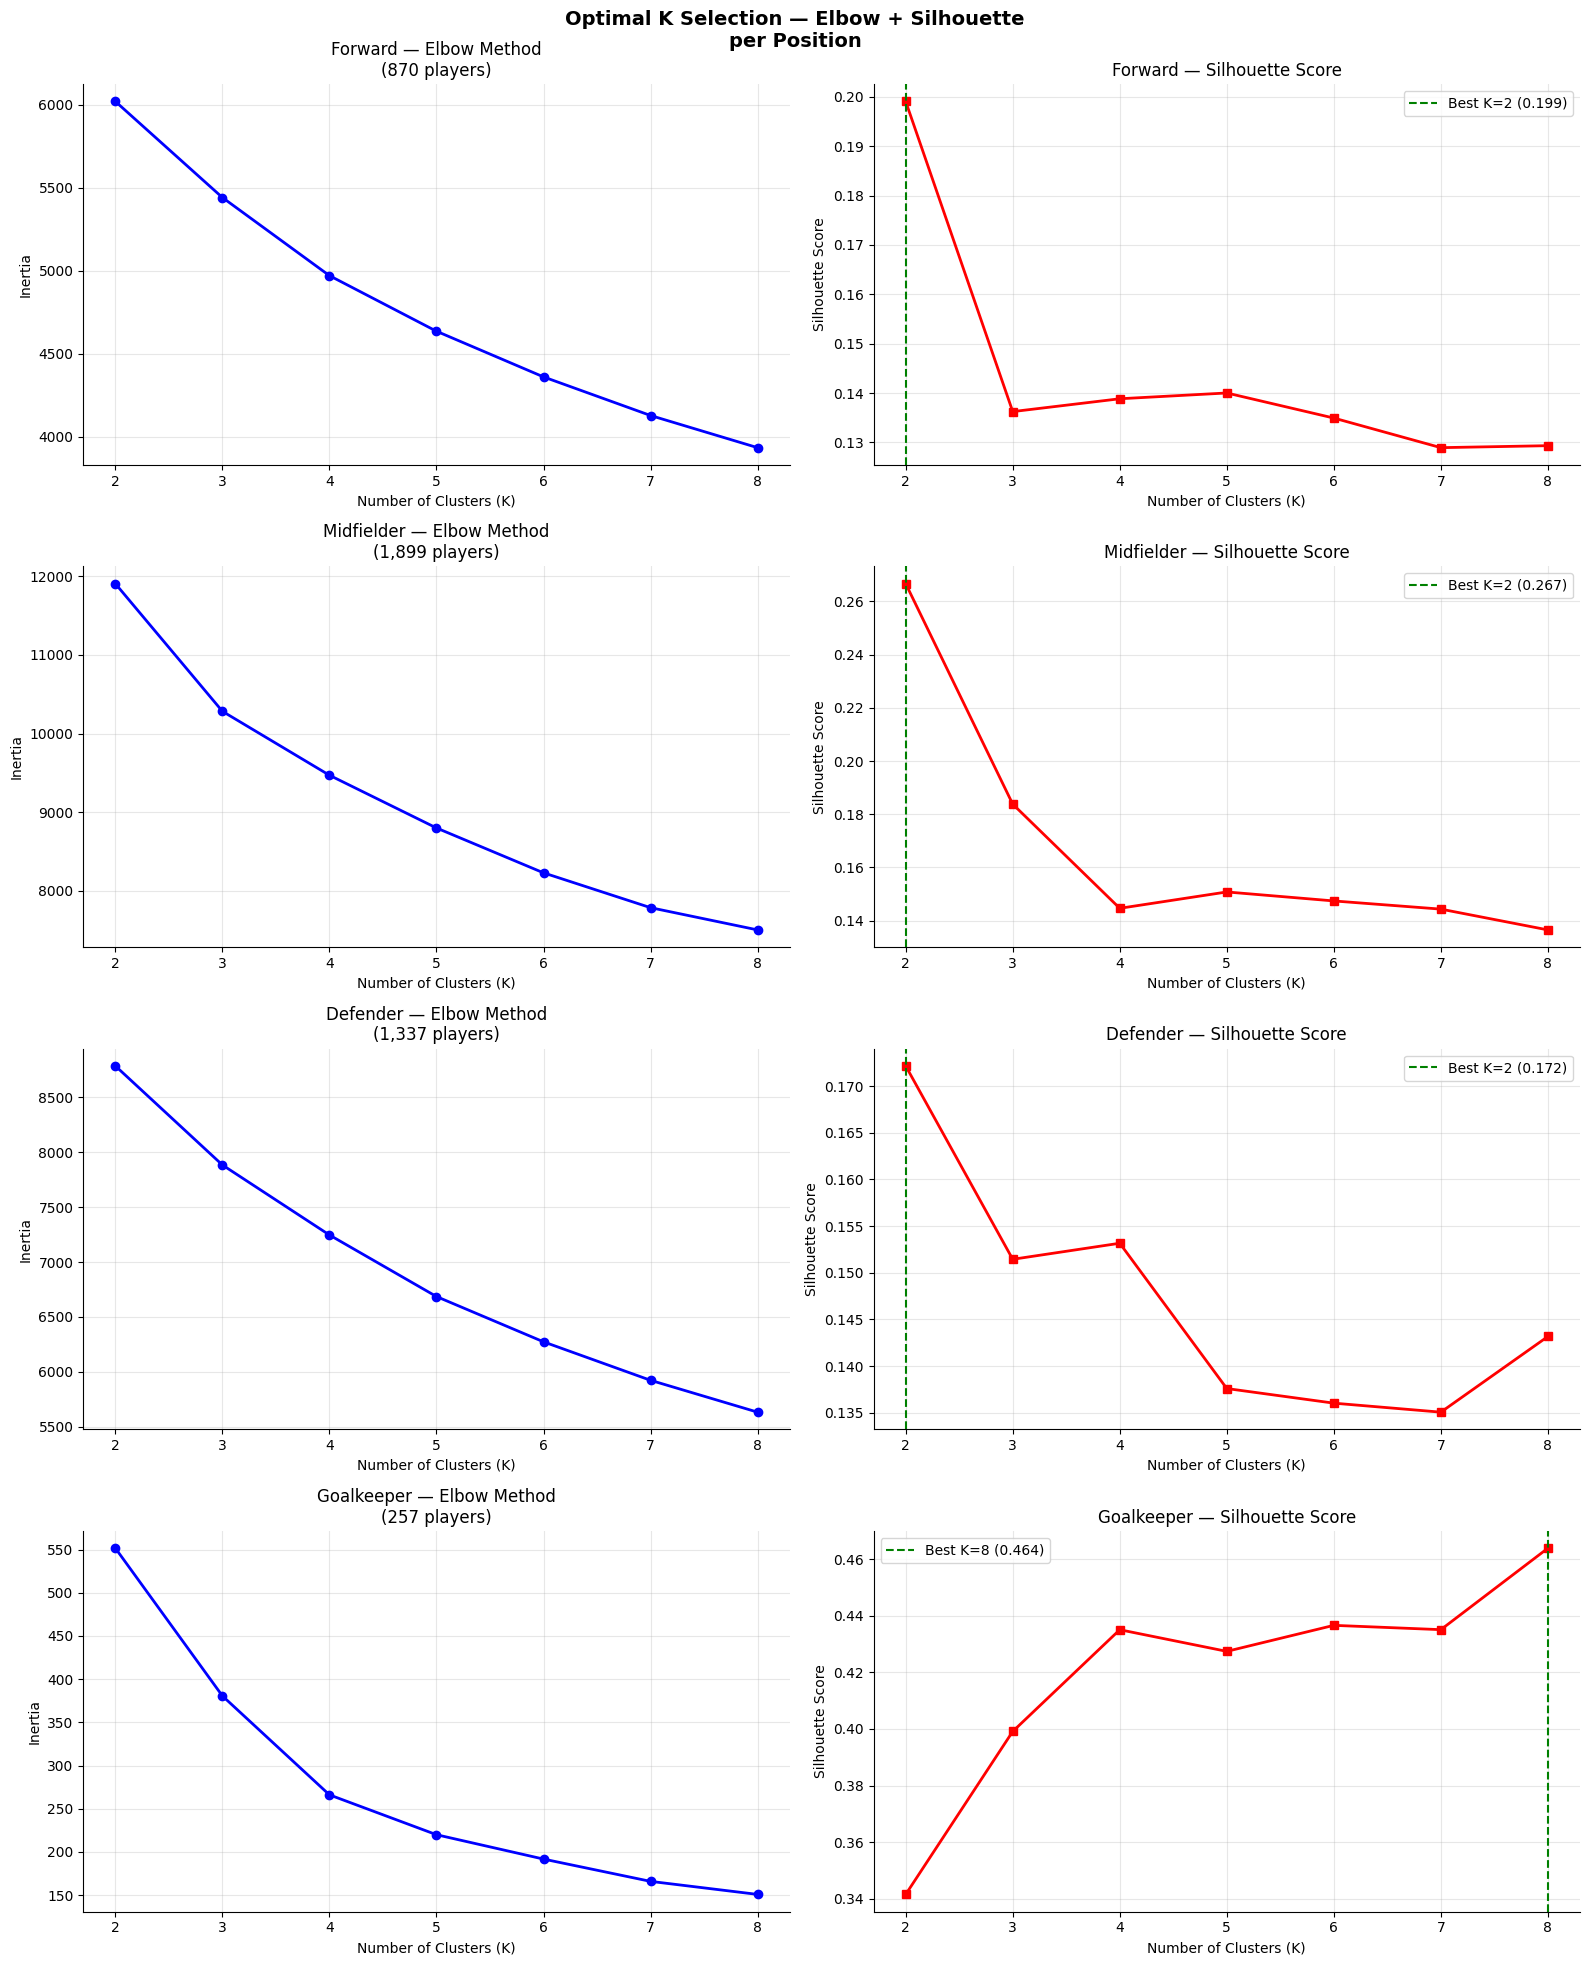

💾 Saved → reports/14_optimal_k.png


In [4]:
def prepare_position_data(pos_name, min_minutes=450):
    """
    Get scaled feature matrix for one position group.
    Uses multi-hot column: MF,FW player appears in BOTH Forward AND Midfielder.
    """
    pos_col  = POS_COL_MAP[pos_name]
    feats    = [f for f in CLUSTER_FEATURES[pos_name] if f in player_latest.columns]

    # Filter by position using multi-hot column
    mask = (player_latest[pos_col] == 1) & \
           (player_latest['minutes_played'] >= min_minutes)

    sub = player_latest[mask].copy()

    # Convert and fill
    X = sub[feats].copy()
    for col in feats:
        X[col] = pd.to_numeric(X[col], errors='coerce')
        if col in ['pos_FW','pos_MF','pos_DF','pos_GK']:
            X[col] = X[col].fillna(0)
        else:
            col_median = X[col].median()
            X[col] = X[col].fillna(0 if pd.isna(col_median) else col_median)

    # Drop rows still containing NaN (safety net for KMeans)
    valid_mask = X.notna().all(axis=1)
    X   = X[valid_mask].copy()
    sub = sub[valid_mask].copy()

    # Clip outliers at 99th percentile
    for col in feats:
        cap = X[col].quantile(0.99)
        if pd.isna(cap) or cap == 0:
            cap = X[col].max()
        X[col] = X[col].clip(upper=cap)

    # Final safety: replace any residual NaN with 0
    X = X.fillna(0)

    # Scale
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    return sub, X_scaled, feats, scaler


def find_optimal_k(X_scaled, k_range=range(2, 9)):
    """Compute inertia + silhouette score for each k."""
    inertias, silhouettes = [], []

    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(X_scaled)
        inertias.append(km.inertia_)
        sil = silhouette_score(X_scaled, labels) if k > 1 else 0
        silhouettes.append(sil)

    return list(k_range), inertias, silhouettes


# ── Run for all positions ─────────────────────────────────
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
fig.suptitle('Optimal K Selection — Elbow + Silhouette\nper Position',
             fontsize=14, fontweight='bold')

k_results = {}
K_RANGE   = range(2, 9)

for i, pos in enumerate(['Forward','Midfielder','Defender','Goalkeeper']):
    sub, X_scaled, feats, scaler = prepare_position_data(pos)
    ks, inertias, silhouettes    = find_optimal_k(X_scaled, K_RANGE)
    k_results[pos] = {'ks':ks,'inertias':inertias,'silhouettes':silhouettes,
                       'n_players':len(sub)}

    # Elbow
    ax = axes[i][0]
    ax.plot(ks, inertias, 'bo-', linewidth=2, markersize=6)
    ax.set_title(f'{pos} — Elbow Method\n({len(sub):,} players)')
    ax.set_xlabel('Number of Clusters (K)')
    ax.set_ylabel('Inertia')

    # Silhouette
    ax = axes[i][1]
    ax.plot(ks, silhouettes, 'rs-', linewidth=2, markersize=6)
    best_k = ks[np.argmax(silhouettes)]
    ax.axvline(best_k, color='green', linestyle='--',
               label=f'Best K={best_k} ({max(silhouettes):.3f})')
    ax.set_title(f'{pos} — Silhouette Score')
    ax.set_xlabel('Number of Clusters (K)')
    ax.set_ylabel('Silhouette Score')
    ax.legend()

    print(f'{pos}: n={len(sub):,}  best K={best_k}  silhouette={max(silhouettes):.3f}')

plt.tight_layout()
plt.savefig(REPORTS/'14_optimal_k.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/14_optimal_k.png')

## 🤖 4 — Train K-Means Per Position
Use the best K found above (or override manually if the automatic pick doesn't make sense).

In [5]:
# ── Override K if needed ─────────────────────────────────
# Adjust these based on the elbow/silhouette charts above
# Rule: choose K that makes INTERPRETABLE clusters (4-6 is usually best)
K_OVERRIDE = {
    'Forward':    4,   # Poacher, Complete, Wide, Target
    'Midfielder': 5,   # Playmaker, Box-to-Box, Creative, Pressing, Defensive
    'Defender':   4,   # Ball-playing, Aggressive, Attacking FB, Conservative
    'Goalkeeper': 3,   # Shot-stopper, Sweeper, Rotated/Low-mins
}

# ── Train one KMeans per position ────────────────────────
cluster_models  = {}   # {pos: {'model':km, 'scaler':scaler, 'features':feats}}
cluster_results = {}   # {pos: DataFrame with cluster labels}

for pos in ['Forward','Midfielder','Defender','Goalkeeper']:
    k = K_OVERRIDE[pos]
    sub, X_scaled, feats, scaler = prepare_position_data(pos)

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,        # 20 random restarts → stable solution
        max_iter=500
    )
    labels = km.fit_predict(X_scaled)
    sil    = silhouette_score(X_scaled, labels)

    sub = sub.copy()
    sub['cluster_id']  = labels
    sub['position_group'] = pos
    sub['sil_score']   = silhouette_samples(X_scaled, labels)

    cluster_models[pos]  = {'model':km,'scaler':scaler,'features':feats,'k':k}
    cluster_results[pos] = sub

    print(f'✅ {pos:<12} k={k}  silhouette={sil:.3f}  n={len(sub):,}')

✅ Forward      k=4  silhouette=0.137  n=870
✅ Midfielder   k=5  silhouette=0.151  n=1,899
✅ Defender     k=4  silhouette=0.152  n=1,337
✅ Goalkeeper   k=3  silhouette=0.399  n=257


## 🏷️ 5 — Name the Clusters
For each cluster, look at the centroid stats and assign a meaningful scout-friendly label.

In [6]:
def profile_clusters(pos, sub_df, feats):
    """
    For each cluster, compute the mean of each feature
    and return a profile DataFrame.
    """
    numeric_feats = [f for f in feats if f in sub_df.columns]
    for f in numeric_feats:
        sub_df[f] = pd.to_numeric(sub_df[f], errors='coerce')

    profile = sub_df.groupby('cluster_id')[numeric_feats].mean().round(3)
    profile['n_players'] = sub_df.groupby('cluster_id').size()
    return profile


# ── Cluster naming rules per position ────────────────────
# Based on centroid analysis — highest/lowest feature values
# These names will be CONFIRMED by the profiles printed below

def auto_name_clusters(pos, profile):
    """
    Automatically name clusters based on their feature profile.
    Returns a dict {cluster_id: name}.
    """
    names = {}

    if pos == 'Forward':
        for cid, row in profile.iterrows():
            high_goals   = row.get('goals_p90',0)   > profile['goals_p90'].median()   if 'goals_p90'   in profile.columns else False
            high_assists = row.get('assists_p90',0)  > profile['assists_p90'].median() if 'assists_p90'  in profile.columns else False
            high_shots   = row.get('shots_p90',0)    > profile['shots_p90'].median()   if 'shots_p90'   in profile.columns else False
            high_conv    = row.get('conversion_rate',0) > profile['conversion_rate'].median() if 'conversion_rate' in profile.columns else False

            if high_goals and not high_assists and high_conv:
                names[cid] = 'Pure Poacher'
            elif high_goals and high_assists:
                names[cid] = 'Complete Forward'
            elif not high_goals and high_assists:
                names[cid] = 'Wide Forward'
            else:
                names[cid] = 'Target Man'

    elif pos == 'Midfielder':
        for cid, row in profile.iterrows():
            high_goals   = row.get('goals_p90',0)      > profile['goals_p90'].median()      if 'goals_p90'      in profile.columns else False
            high_assists = row.get('assists_p90',0)     > profile['assists_p90'].median()    if 'assists_p90'    in profile.columns else False
            high_def     = row.get('def_actions_p90',0) > profile['def_actions_p90'].median() if 'def_actions_p90' in profile.columns else False
            high_tkl     = row.get('tackles_won_p90',0) > profile['tackles_won_p90'].median() if 'tackles_won_p90' in profile.columns else False
            high_int     = row.get('interceptions_p90',0) > profile['interceptions_p90'].median() if 'interceptions_p90' in profile.columns else False

            if high_goals and high_assists:
                names[cid] = 'Creative #10'
            elif high_def and high_tkl and high_int:
                names[cid] = 'Defensive Midfielder'
            elif high_def and (high_goals or high_assists):
                names[cid] = 'Box-to-Box'
            elif high_tkl and not high_goals:
                names[cid] = 'Pressing Machine'
            else:
                names[cid] = 'Deep Playmaker'

    elif pos == 'Defender':
        for cid, row in profile.iterrows():
            high_assists = row.get('assists_p90',0)     > profile['assists_p90'].median()    if 'assists_p90'    in profile.columns else False
            high_tkl     = row.get('tackles_won_p90',0) > profile['tackles_won_p90'].median() if 'tackles_won_p90' in profile.columns else False
            high_int     = row.get('interceptions_p90',0) > profile['interceptions_p90'].median() if 'interceptions_p90' in profile.columns else False
            high_yel     = row.get('yellow_p90',0)      > profile['yellow_p90'].median()     if 'yellow_p90'     in profile.columns else False

            if high_assists and not high_tkl:
                names[cid] = 'Attacking Fullback'
            elif high_tkl and high_yel:
                names[cid] = 'Aggressive Stopper'
            elif high_int and not high_yel:
                names[cid] = 'Ball-Playing CB'
            else:
                names[cid] = 'Defensive CB'

    elif pos == 'Goalkeeper':
        for cid, row in profile.iterrows():
            high_avail = row.get('availability_pct',0) > profile['availability_pct'].median() if 'availability_pct' in profile.columns else False
            high_def   = row.get('def_actions_p90',0)  > profile['def_actions_p90'].median()  if 'def_actions_p90'  in profile.columns else False

            if high_avail and high_def:
                names[cid] = 'Sweeper Keeper'
            elif high_avail:
                names[cid] = 'Shot-stopper'
            else:
                names[cid] = 'Backup GK'

    # Fallback: number remaining unnamed
    existing = set(names.values())
    counter  = 1
    for cid in profile.index:
        if cid not in names:
            label = f'{pos} Type {counter}'
            while label in existing:
                counter += 1
                label = f'{pos} Type {counter}'
            names[cid] = label
            existing.add(label)
            counter += 1

    return names


# ── Print profiles and name clusters ─────────────────────
all_names = {}

for pos in ['Forward','Midfielder','Defender','Goalkeeper']:
    sub   = cluster_results[pos]
    feats = cluster_models[pos]['features']

    profile = profile_clusters(pos, sub, feats)
    names   = auto_name_clusters(pos, profile)
    all_names[pos] = names

    # Add name to results
    cluster_results[pos]['style_label'] = cluster_results[pos]['cluster_id'].map(names)

    print(f'\n{"="*60}')
    print(f'  {pos.upper()} CLUSTERS')
    print(f'{"="*60}')
    for cid, name in names.items():
        n = (sub['cluster_id'] == cid).sum()
        print(f'  Cluster {cid} → [{name}]  ({n:,} players)')
    print()
    print(profile.to_string())


  FORWARD CLUSTERS
  Cluster 0 → [Target Man]  (263 players)
  Cluster 1 → [Complete Forward]  (135 players)
  Cluster 2 → [Pure Poacher]  (272 players)
  Cluster 3 → [Wide Forward]  (200 players)

            goals_p90  assists_p90  shots_p90  shot_accuracy_pct  conversion_rate  g_a_p90  tackles_won_p90  yellow_p90  availability_pct  n_players
cluster_id                                                                                                                                          
0               0.087        0.077      1.784             30.250            0.047    0.164            0.853       0.209            62.385        263
1               0.603        0.171      3.038             45.589            0.182    0.774            0.461       0.155            75.807        135
2               0.300        0.066      2.238             40.694            0.132    0.366            0.421       0.190            63.696        272
3               0.225        0.256      2.254           

In [7]:
# ── Manual override: rename clusters after inspecting profiles ─
# Edit this dict if the auto-names don't match what you see in the profiles above
# Format: {position: {cluster_id: 'New Name'}}
MANUAL_NAMES = {
    # Example: if cluster 2 for Forwards looks like a Wide Forward not Target Man, fix it:
    # 'Forward':    {2: 'Wide Forward'},
    # 'Midfielder': {0: 'Regista'},
}

# Apply manual overrides
for pos, overrides in MANUAL_NAMES.items():
    for cid, new_name in overrides.items():
        old_name = all_names[pos].get(cid, '?')
        all_names[pos][cid] = new_name
        cluster_results[pos].loc[
            cluster_results[pos]['cluster_id'] == cid, 'style_label'
        ] = new_name
        print(f'  ✏️  {pos} cluster {cid}: {old_name} → {new_name}')

print('Cluster names finalized:')
for pos, names in all_names.items():
    print(f'  {pos}: {list(names.values())}')

Cluster names finalized:
  Forward: ['Target Man', 'Complete Forward', 'Pure Poacher', 'Wide Forward']
  Midfielder: ['Deep Playmaker', 'Defensive Midfielder', 'Deep Playmaker', 'Box-to-Box', 'Creative #10']
  Defender: ['Defensive CB', 'Defensive CB', 'Aggressive Stopper', 'Defensive CB']
  Goalkeeper: ['Backup GK', 'Shot-stopper', 'Backup GK']


## 📊 6 — Visualize: PCA Cluster Plot per Position

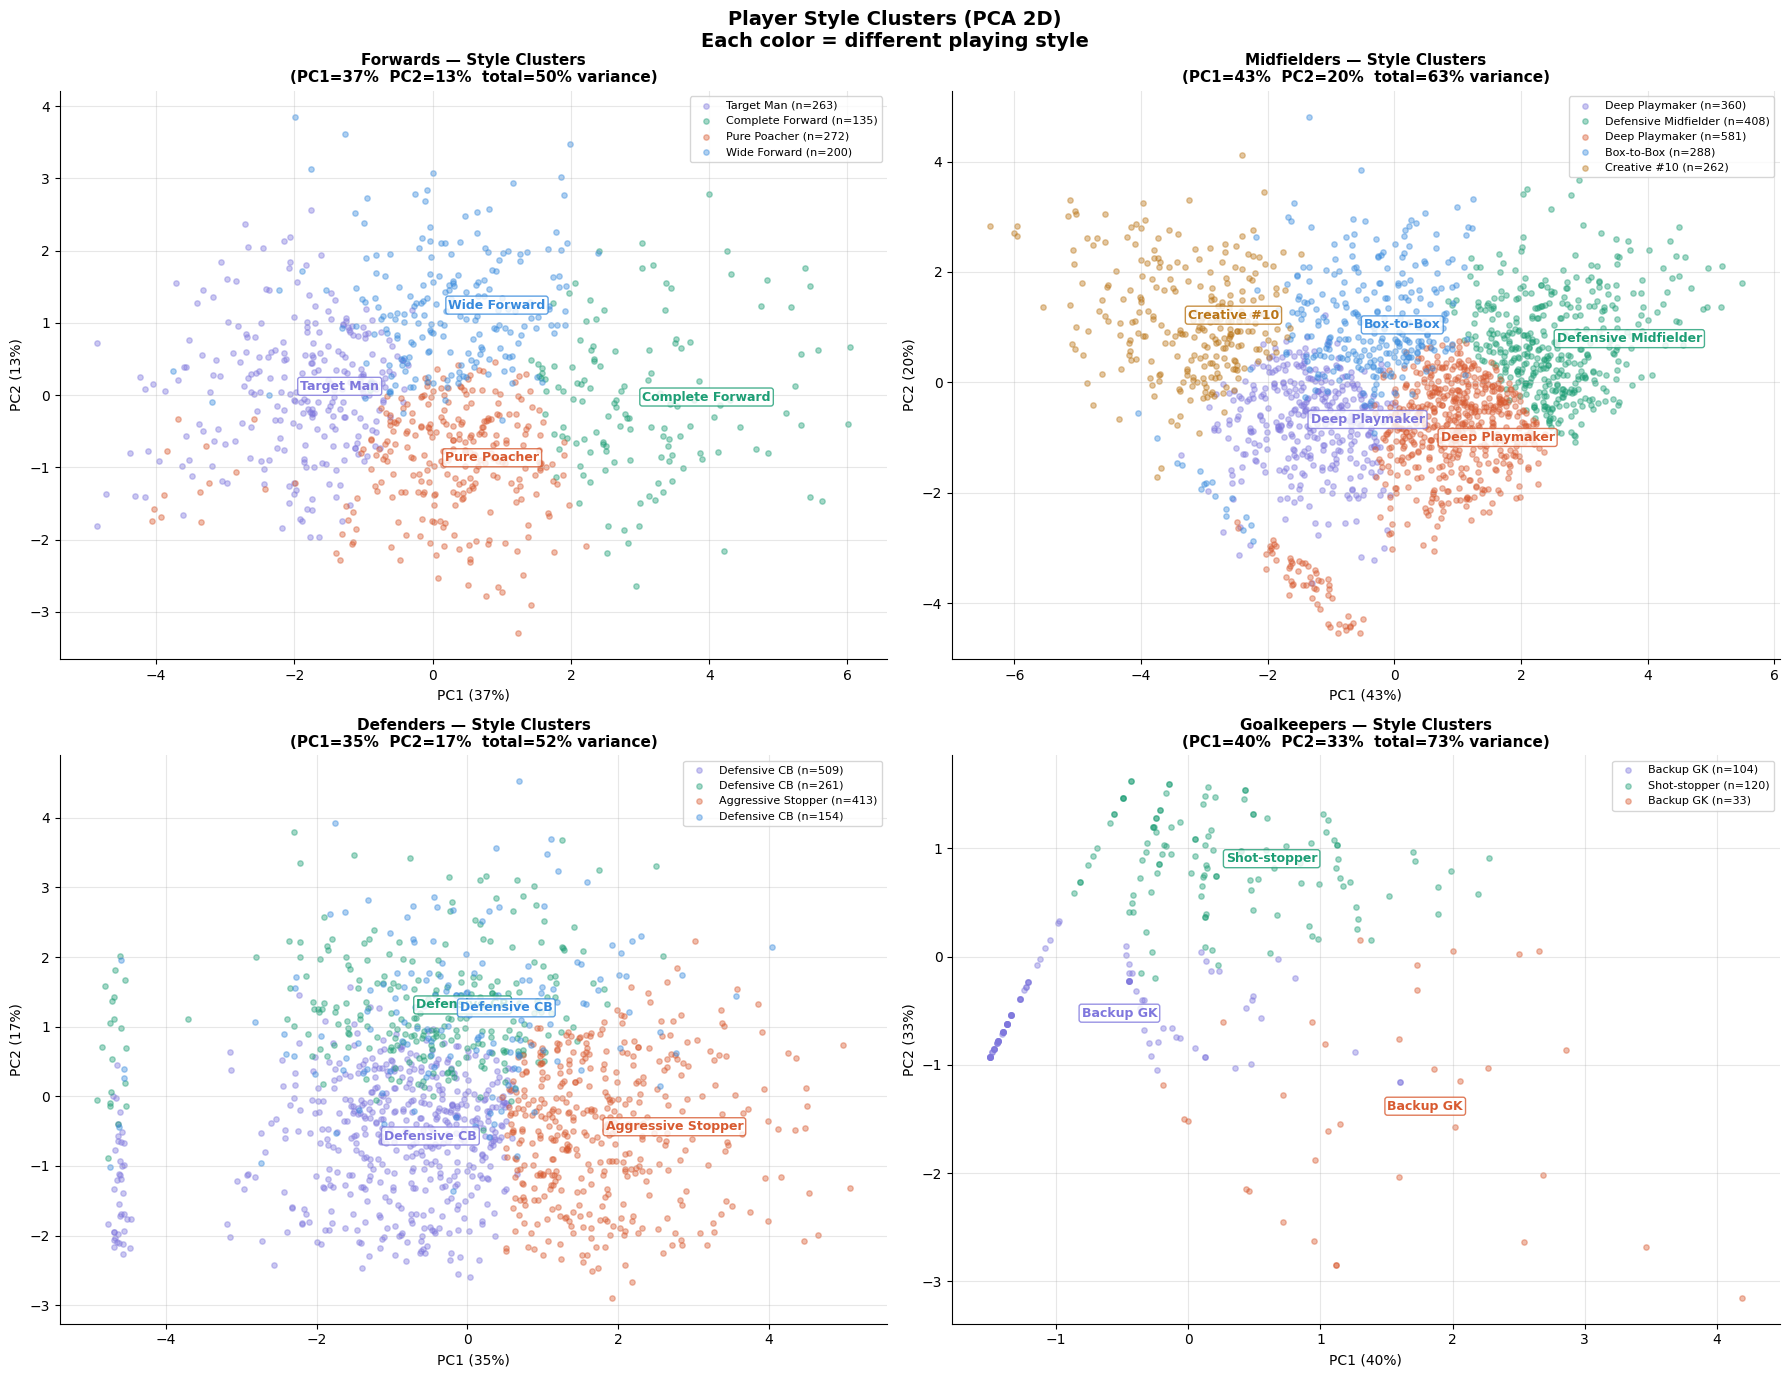

💾 Saved → reports/15_style_clusters_pca.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Player Style Clusters (PCA 2D)\nEach color = different playing style',
             fontsize=14, fontweight='bold')
axes = axes.flatten()

for i, pos in enumerate(['Forward','Midfielder','Defender','Goalkeeper']):
    sub    = cluster_results[pos]
    feats  = cluster_models[pos]['features']
    scaler = cluster_models[pos]['scaler']
    names  = all_names[pos]
    ax     = axes[i]

    # Scale
    X = sub[[f for f in feats if f in sub.columns]].copy()
    for col in X.columns:
        X[col] = pd.to_numeric(X[col], errors='coerce').fillna(0)
        cap = X[col].quantile(0.99)
        X[col] = X[col].clip(upper=cap)

    X_scaled = scaler.transform(X)

    # PCA 2D
    pca  = PCA(n_components=2, random_state=42)
    X_2d = pca.fit_transform(X_scaled)
    var  = pca.explained_variance_ratio_ * 100

    # Plot each cluster
    unique_clusters = sorted(sub['cluster_id'].unique())
    for j, cid in enumerate(unique_clusters):
        mask  = sub['cluster_id'] == cid
        label = names.get(cid, f'Cluster {cid}')
        color = COLORS[j % len(COLORS)]

        ax.scatter(
            X_2d[mask, 0], X_2d[mask, 1],
            c=color, alpha=0.4, s=15, label=f'{label} (n={mask.sum():,})'
        )

        # Cluster centroid label
        cx = X_2d[mask, 0].mean()
        cy = X_2d[mask, 1].mean()
        ax.annotate(
            label, (cx, cy),
            fontsize=9, fontweight='bold', color=color,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                      edgecolor=color, alpha=0.8)
        )

    ax.set_title(f'{pos}s — Style Clusters\n'
                 f'(PC1={var[0]:.0f}%  PC2={var[1]:.0f}%  '
                 f'total={sum(var):.0f}% variance)',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel(f'PC1 ({var[0]:.0f}%)')
    ax.set_ylabel(f'PC2 ({var[1]:.0f}%)')
    ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig(REPORTS/'15_style_clusters_pca.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/15_style_clusters_pca.png')

## 📊 7 — Visualize: Cluster Radar Profiles

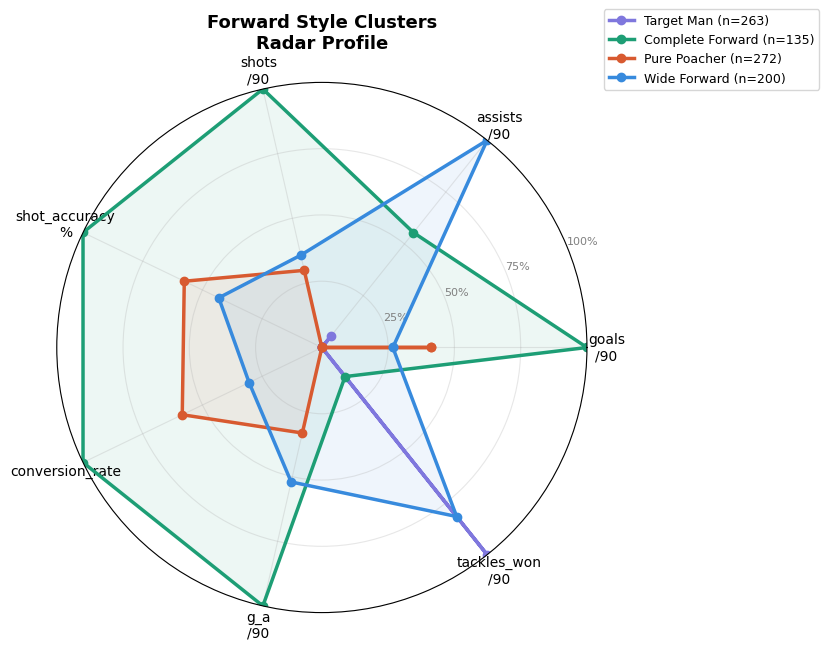

💾 Saved → reports/16_radar_forward.png


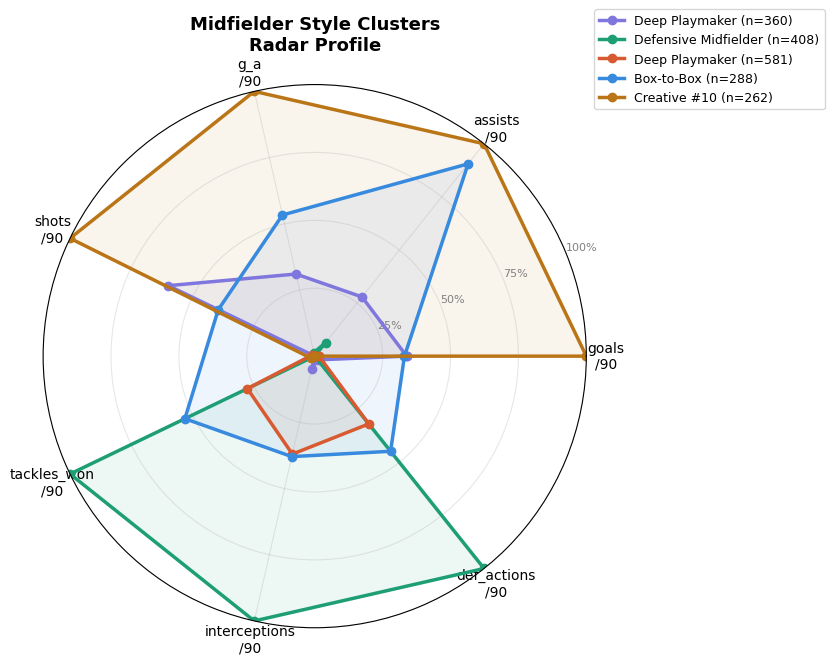

💾 Saved → reports/16_radar_midfielder.png


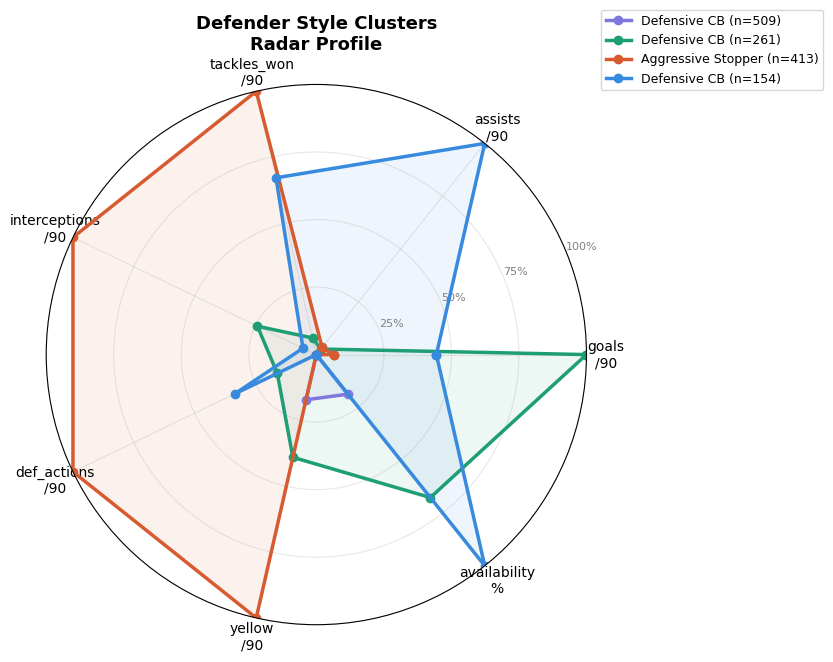

💾 Saved → reports/16_radar_defender.png


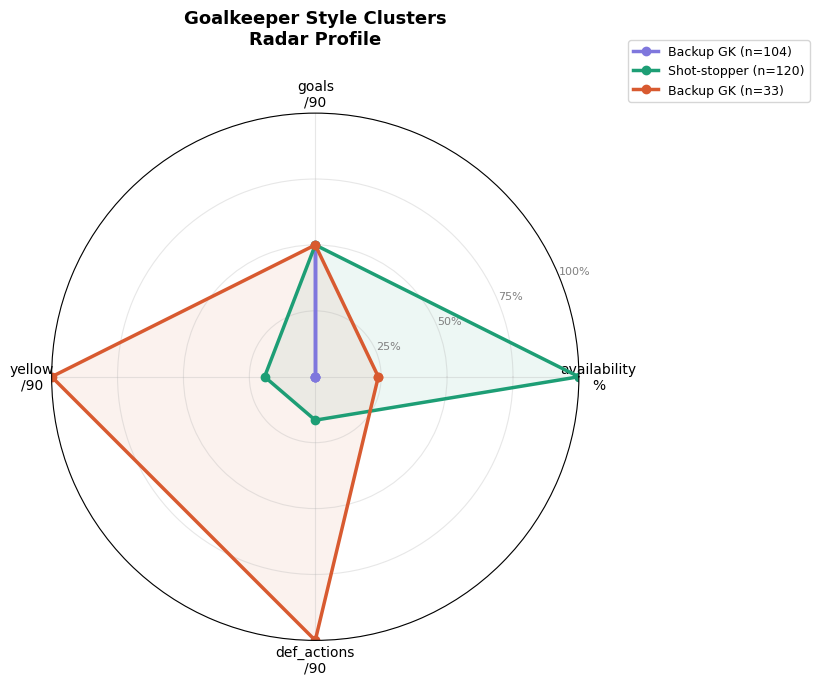

💾 Saved → reports/16_radar_goalkeeper.png


In [9]:
def plot_cluster_radar(pos, sub_df, feats, names, max_display_feats=7):
    """
    Radar chart showing each cluster's average profile.
    Makes it easy to see how clusters differ from each other.
    """
    display_feats = [f for f in feats if f in sub_df.columns][:max_display_feats]
    labels = [f.replace('_p90','\n/90').replace('_pct','\n%') for f in display_feats]
    n_cats = len(display_feats)

    if n_cats < 3: return

    # Compute cluster means (normalized 0-1)
    for f in display_feats:
        sub_df[f] = pd.to_numeric(sub_df[f], errors='coerce').fillna(0)

    cluster_means = sub_df.groupby('cluster_id')[display_feats].mean()

    # Normalize per feature
    for col in display_feats:
        mn, mx = cluster_means[col].min(), cluster_means[col].max()
        if mx > mn:
            cluster_means[col] = (cluster_means[col] - mn) / (mx - mn)
        else:
            cluster_means[col] = 0.5

    angles = np.linspace(0, 2 * np.pi, n_cats, endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

    for j, (cid, row) in enumerate(cluster_means.iterrows()):
        values = row.values.tolist() + row.values[:1].tolist()
        name   = names.get(cid, f'Cluster {cid}')
        color  = COLORS[j % len(COLORS)]
        n_pl   = (sub_df['cluster_id'] == cid).sum()

        ax.plot(angles, values, 'o-', linewidth=2.5, color=color,
                label=f'{name} (n={n_pl:,})')
        ax.fill(angles, values, alpha=0.08, color=color)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(['25%','50%','75%','100%'], fontsize=8, color='gray')
    ax.set_title(f'{pos} Style Clusters\nRadar Profile',
                 fontsize=13, fontweight='bold', pad=25)
    ax.legend(loc='upper right', bbox_to_anchor=(1.45, 1.15), fontsize=9)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(REPORTS / f'16_radar_{pos.lower()}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'💾 Saved → reports/16_radar_{pos.lower()}.png')


for pos in ['Forward','Midfielder','Defender','Goalkeeper']:
    plot_cluster_radar(
        pos,
        cluster_results[pos].copy(),
        cluster_models[pos]['features'],
        all_names[pos]
    )

## 🔍 8 — Validate: Famous Players in Their Clusters

In [10]:
# ── Who's in each cluster? Spot check with known players ─
print('='*60)
print('  CLUSTER VALIDATION — FAMOUS PLAYERS')
print('='*60)

SPOT_CHECK = {
    'Forward':    ['Lewandowski','Haaland','Mbappé','Benzema','Kane',
                   'Salah','Son','Werner','Firmino','Giroud'],
    'Midfielder': ['Modric','Kroos','De Bruyne','Kante','Busquets',
                   'Müller','Fernandes','Rice','Mount','Verratti'],
    'Defender':   ['Van Dijk','Alaba','Cancelo','Robertson','Alexander-Arnold',
                   'Dias','Rüdiger','Militao','Pavard'],
    'Goalkeeper': ['Alisson','Ederson','De Gea','Courtois','Neuer'],
}

for pos, players_list in SPOT_CHECK.items():
    sub   = cluster_results[pos]
    names = all_names[pos]
    print(f'\n── {pos}s ──────────────────────────────────────')

    for name in players_list:
        mask = sub['Player'].str.contains(name, case=False, na=False)
        if mask.any():
            row   = sub[mask].iloc[0]
            cid   = int(row['cluster_id'])
            label = names.get(cid, f'Cluster {cid}')
            goals = row.get('goals_p90', 0)
            ast   = row.get('assists_p90', 0)
            tkl   = row.get('tackles_won_p90', 0)
            print(f'  {row["Player"]:<25} → [{label:<20}]  '
                  f'G/90:{goals:.2f}  A/90:{ast:.2f}  Tkl/90:{tkl:.2f}')
        else:
            print(f'  {name:<25} → not found in {pos} index')

  CLUSTER VALIDATION — FAMOUS PLAYERS

── Forwards ──────────────────────────────────────
  Robert Lewandowski        → [Complete Forward    ]  G/90:0.91  A/90:0.07  Tkl/90:0.17
  Erling Haaland            → [Complete Forward    ]  G/90:0.72  A/90:0.10  Tkl/90:0.20
  Kylian Mbappé             → [Complete Forward    ]  G/90:0.96  A/90:0.09  Tkl/90:0.15
  Karim Benzema             → [Complete Forward    ]  G/90:0.84  A/90:0.13  Tkl/90:0.22
  Harry Kane                → [Complete Forward    ]  G/90:0.98  A/90:0.34  Tkl/90:0.38
  Salah                     → not found in Forward index
  Orri Steinn Óskarsson     → [Pure Poacher        ]  G/90:0.29  A/90:0.00  Tkl/90:0.57
  Timo Werner               → [Wide Forward        ]  G/90:0.00  A/90:0.52  Tkl/90:0.70
  Roberto Firmino           → [Complete Forward    ]  G/90:0.82  A/90:0.30  Tkl/90:0.96
  Olivier Giroud            → [Complete Forward    ]  G/90:0.57  A/90:0.30  Tkl/90:0.42

── Midfielders ──────────────────────────────────────
  Modr

## 📊 9 — Cluster Stats Summary Table

In [11]:
# ── Summary stats per cluster ─────────────────────────────
for pos in ['Forward','Midfielder','Defender','Goalkeeper']:
    sub   = cluster_results[pos]
    names = all_names[pos]
    feats = cluster_models[pos]['features']

    # Convert features to numeric
    for f in feats:
        if f in sub.columns:
            sub[f] = pd.to_numeric(sub[f], errors='coerce')

    show_cols = [
        c for c in feats[:6] + ['market_value_eur']
        if c in sub.columns
    ]

    summary = sub.groupby('style_label')[show_cols].mean().round(3)
    summary['n_players'] = sub.groupby('style_label').size()

    if 'market_value_eur' in summary.columns:
        summary['avg_value_M'] = (summary['market_value_eur'] / 1e6).round(1)
        summary.drop(columns=['market_value_eur'], inplace=True)

    print(f'\n{"="*65}')
    print(f'  {pos.upper()} CLUSTER PROFILES')
    print(f'{"="*65}')
    print(summary.to_string())


  FORWARD CLUSTER PROFILES
                  goals_p90  assists_p90  shots_p90  shot_accuracy_pct  conversion_rate  g_a_p90  n_players  avg_value_M
style_label                                                                                                             
Complete Forward      0.603        0.171      3.038             45.589            0.182    0.774        135       26.900
Pure Poacher          0.300        0.066      2.238             40.694            0.132    0.366        272        6.400
Target Man            0.087        0.077      1.784             30.250            0.047    0.164        263        5.300
Wide Forward          0.225        0.256      2.254             37.265            0.089    0.482        200       14.000

  MIDFIELDER CLUSTER PROFILES
                      goals_p90  assists_p90  g_a_p90  shots_p90  tackles_won_p90  interceptions_p90  n_players  avg_value_M
style_label                                                                               

## 💾 10 — Build Combined Output & Save

In [12]:
# ── Combine all position clusters into one DataFrame ─────
all_clustered = []

for pos in ['Forward','Midfielder','Defender','Goalkeeper']:
    sub = cluster_results[pos][[
        'Player','name_norm','primary_pos','pos_FW','pos_MF','pos_DF','pos_GK',
        'is_versatile','Squad','league','season','Age',
        'cluster_id','style_label','position_group','sil_score',
        'goals_p90','assists_p90','tackles_won_p90','def_actions_p90',
        'availability_pct','market_value_eur'
    ]].copy()

    # Add talent score if available
    if not talent_df.empty:
        sub = sub.merge(
            talent_df[['Player','predicted_talent','talent_label']],
            on='Player', how='left'
        )

    all_clustered.append(sub)

style_df = pd.concat(all_clustered, ignore_index=True)

# Note: versatile players (MF,FW) appear TWICE — once in Forward, once in Midfielder
# This is intentional — they belong to both clusters
print(f'Total cluster assignments: {len(style_df):,}')
print(f'Unique players: {style_df["Player"].nunique():,}')
print(f'(versatile players appear in multiple position clusters)')
print()
print('Style label distribution:')
print(style_df['style_label'].value_counts().to_string())

# Save
style_df.to_csv(PROCESSED / 'style_clusters.csv', index=False)
print(f'\n💾 Saved → data/processed/style_clusters.csv')

# Save cluster models
with open(PROCESSED / 'cluster_models.pkl', 'wb') as f:
    pickle.dump({'models': cluster_models, 'names': all_names}, f)
print(f'💾 Saved → data/processed/cluster_models.pkl')

Total cluster assignments: 4,363
Unique players: 3,451
(versatile players appear in multiple position clusters)

Style label distribution:
style_label
Deep Playmaker          941
Defensive CB            924
Aggressive Stopper      413
Defensive Midfielder    408
Box-to-Box              288
Pure Poacher            272
Target Man              263
Creative #10            262
Wide Forward            200
Backup GK               137
Complete Forward        135
Shot-stopper            120

💾 Saved → data/processed/style_clusters.csv
💾 Saved → data/processed/cluster_models.pkl


## 🔍 11 — Scouting Use Case: Find Players by Style

In [13]:
def find_by_style(style_label, max_budget_eur=None, min_talent_score=None,
                  league=None, max_age=None, top_n=10):
    """
    Find players with a specific style label.
    This is the KEY function for the recommendation engine.

    Example: find_by_style('Box-to-Box', max_budget_eur=25_000_000, min_talent_score=60)
    """
    result = style_df[style_df['style_label'] == style_label].copy()

    if result.empty:
        print(f'❌ Style label "{style_label}" not found')
        print(f'   Available styles: {sorted(style_df["style_label"].unique())}')
        return pd.DataFrame()

    if max_budget_eur:
        mv = pd.to_numeric(result['market_value_eur'], errors='coerce')
        result = result[mv.fillna(np.inf) <= max_budget_eur]

    if min_talent_score is not None and 'predicted_talent' in result.columns:
        result = result[pd.to_numeric(
            result['predicted_talent'], errors='coerce'
        ).fillna(0) >= min_talent_score]

    if league:
        result = result[result['league'] == league]

    if max_age:
        result = result[pd.to_numeric(result['Age'], errors='coerce').fillna(99) <= max_age]

    # Sort by talent score if available, else by goals_p90
    sort_col = 'predicted_talent' if 'predicted_talent' in result.columns else 'goals_p90'
    result   = result.sort_values(
        sort_col, ascending=False, key=lambda x: pd.to_numeric(x, errors='coerce')
    ).head(top_n)

    display_cols = ['Player','Age','Squad','league','season',
                    'goals_p90','assists_p90','tackles_won_p90',
                    'market_value_eur'] + (
        ['predicted_talent'] if 'predicted_talent' in result.columns else []
    )
    display_cols = [c for c in display_cols if c in result.columns]

    print(f'🔍 Style: [{style_label}]  → {len(result)} players found')
    return result[display_cols]


# Test use cases
print('='*60)
print('USE CASE 1: Find Box-to-Box midfielders under €30M')
print('='*60)
r1 = find_by_style('Box-to-Box', max_budget_eur=30_000_000)
print(r1.to_string(index=False))

print('\n' + '='*60)
print('USE CASE 2: Find Complete Forwards, talent > 65, age ≤ 25')
print('='*60)
r2 = find_by_style('Complete Forward', min_talent_score=65, max_age=25)
print(r2.to_string(index=False))

print('\n' + '='*60)
print('USE CASE 3: Find Attacking Fullbacks in EPL')
print('='*60)
r3 = find_by_style('Attacking Fullback', league='EPL')
print(r3.to_string(index=False))

USE CASE 1: Find Box-to-Box midfielders under €30M
🔍 Style: [Box-to-Box]  → 10 players found
          Player    Age           Squad     league    season  goals_p90  assists_p90  tackles_won_p90  market_value_eur  predicted_talent
  Patrick Wimmer 23.000       Wolfsburg Bundesliga 2024-2025      0.153        0.203            1.678      15000000.000            84.100
        Ali Abdi 30.000            Nice     Ligue1 2024-2025      0.323        0.129            1.744       2500000.000            83.500
   Mateo Kovačić 30.000 Manchester City        EPL 2024-2025      0.246        0.082            1.597      12000000.000            82.600
 Jonathan Clauss 31.000            Nice     Ligue1 2024-2025      0.117        0.313            1.329       4500000.000            82.400
Hakan Çalhanoğlu 30.000           Inter     SerieA 2024-2025      0.231        0.277            1.017      18000000.000            81.000
    Rémy Cabella 34.000           Lille     Ligue1 2024-2025      0.089        

## 🖨️ 12 — Summary Print for Claude

In [14]:
# Build complete summary
cluster_summary = {}
for pos in ['Forward','Midfielder','Defender','Goalkeeper']:
    sub   = cluster_results[pos]
    names = all_names[pos]
    cluster_summary[pos] = {
        'k':           cluster_models[pos]['k'],
        'n_players':   len(sub),
        'features':    cluster_models[pos]['features'],
        'clusters':    {
            names[cid]: int((sub['cluster_id']==cid).sum())
            for cid in sorted(sub['cluster_id'].unique())
        },
    }

summary = {
    'model': {
        'name':              'K-Means per position group',
        'positions':         list(cluster_models.keys()),
        'k_per_position':    {p: cluster_models[p]['k'] for p in cluster_models},
        'scaling':           'StandardScaler + 99th percentile clip',
        'selection':         'Elbow + Silhouette score',
    },
    'design_decisions': [
        'Separate K-Means per position — no cross-position comparison',
        'Multi-hot positions: MF,FW player clustered in BOTH Forward AND Midfielder',
        'Per-90 features only — style not volume',
        'Position-specific feature sets — GK has different features than FW',
        'Manual name override available if auto-names are wrong',
    ],
    'clusters_found': cluster_summary,
    'all_style_labels': sorted(style_df['style_label'].unique().tolist()),
    'api_interface': {
        'find_by_style':     'find_by_style(style_label, max_budget_eur, min_talent_score, league, max_age)',
        'style_labels_list': sorted(style_df['style_label'].unique().tolist()),
    },
    'saved_artifacts': ['style_clusters.csv', 'cluster_models.pkl'],
    'next_notebook': 'notebook 07 — Recommendation Engine (combines all 3 models)',
}

print('='*60)
print('  NB06 COMPLETE — K-MEANS STYLE CLUSTERING')
print('='*60)
print(json.dumps(summary, indent=2, default=str))

with open(PROCESSED/'nb06_summary.json','w') as f:
    json.dump(summary, f, indent=2, default=str)

print(f"""
{'='*60}
  CLUSTERING READY:
  Style labels:     {sorted(style_df['style_label'].unique().tolist())}
  Total assignments:{len(style_df):,}
  → NEXT: notebook 07 — Recommendation Engine
{'='*60}
""")

  NB06 COMPLETE — K-MEANS STYLE CLUSTERING
{
  "model": {
    "name": "K-Means per position group",
    "positions": [
      "Forward",
      "Midfielder",
      "Defender",
      "Goalkeeper"
    ],
    "k_per_position": {
      "Forward": 4,
      "Midfielder": 5,
      "Defender": 4,
      "Goalkeeper": 3
    },
    "scaling": "StandardScaler + 99th percentile clip",
    "selection": "Elbow + Silhouette score"
  },
  "design_decisions": [
    "Separate K-Means per position \u2014 no cross-position comparison",
    "Multi-hot positions: MF,FW player clustered in BOTH Forward AND Midfielder",
    "Per-90 features only \u2014 style not volume",
    "Position-specific feature sets \u2014 GK has different features than FW",
    "Manual name override available if auto-names are wrong"
  ],
  "clusters_found": {
    "Forward": {
      "k": 4,
      "n_players": 870,
      "features": [
        "goals_p90",
        "assists_p90",
        "shots_p90",
        "shot_accuracy_pct",
        "co